In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/komalwahid/finaldata2/final_cleaned (1).csv
/kaggle/input/datasets/komalwahid/labelleddata/final_with_labels.csv
/kaggle/input/datasets/komalwahid/cleaneddataser4/cleaned_file1.csv


In [5]:
import pandas as pd

# load file
df = pd.read_csv('/kaggle/input/datasets/komalwahid/finaldata2/final_cleaned (1).csv')

# check column names
print(df.columns)

# if you want them in list form
print(df.columns.tolist())

Index(['customer_id', 'unique_locations', 'dominant_ratio', 'mobility_type',
       'weekend_ratio', 'dominant_cluster', 'cluster_percentages', 'recency',
       'frequency', 'monetary', 'adaptive_recency'],
      dtype='object')
['customer_id', 'unique_locations', 'dominant_ratio', 'mobility_type', 'weekend_ratio', 'dominant_cluster', 'cluster_percentages', 'recency', 'frequency', 'monetary', 'adaptive_recency']


In [6]:
import pandas as pd

# load file
df = pd.read_csv('/kaggle/input/datasets/komalwahid/finaldata2/final_cleaned (1).csv')

# keep only the columns you want
selected_columns = [
    'customer_id',
    'recency',
    'adaptive_recency',
    'frequency',
    'monetary'
]

# create new dataframe
df_selected = df[selected_columns]

# save new file
df_selected.to_csv('/kaggle/working/final_selected_features.csv', index=False)

print(df_selected.head())
print("New file saved as final_selected_features.csv")

                                         customer_id  recency  \
0  00004f7040e477e00425c48b30bebf1d3a492a4712843e...       23   
1  00007e5d3053beab44473586a38210c51dbfe17feed8d0...       45   
2  0000c714dbf2ad84329b7b79fffcb4f1dd7ed8cce08c12...       27   
3  00011f09a34652c24b92f112682911c1df256f7d89a3fd...       24   
4  0001a900d4d4c7f5ba3769a5c6af5c55a850dc9970ed18...       60   

   adaptive_recency  frequency  monetary  
0          0.032789          1     143.7  
1          0.001247          1      92.5  
2          0.018096          1      34.1  
3          0.028261          1      40.5  
4          0.000134          1      38.5  
New file saved as final_selected_features.csv


DBScan


In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv('/kaggle/working/final_selected_features.csv')

features = ['recency', 'adaptive_recency', 'frequency', 'monetary']

df = df[['customer_id'] + features].copy()
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

print(df.shape)
print(df.head())

(326740, 5)
                                         customer_id  recency  \
0  00004f7040e477e00425c48b30bebf1d3a492a4712843e...       23   
1  00007e5d3053beab44473586a38210c51dbfe17feed8d0...       45   
2  0000c714dbf2ad84329b7b79fffcb4f1dd7ed8cce08c12...       27   
3  00011f09a34652c24b92f112682911c1df256f7d89a3fd...       24   
4  0001a900d4d4c7f5ba3769a5c6af5c55a850dc9970ed18...       60   

   adaptive_recency  frequency  monetary  
0          0.032789          1     143.7  
1          0.001247          1      92.5  
2          0.018096          1      34.1  
3          0.028261          1      40.5  
4          0.000134          1      38.5  


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import pandas as pd
import numpy as np

df = pd.read_csv('/kaggle/input/datasets/komalwahid/finaldata2/final_cleaned (1).csv')

features = ['recency',  'frequency', 'monetary']

df = df[['customer_id'] + features].copy()
df = df.replace([np.inf, -np.inf], np.nan).dropna()

scaler = StandardScaler()
X_full_scaled = scaler.fit_transform(df[features])

print("Full data scaled:", X_full_scaled.shape)

Full data scaled: (326740, 3)


In [9]:
features = ['recency', 'frequency', 'monetary']

X = df[features].astype('float32')

print(X.dtypes)

recency      float32
frequency    float32
monetary     float32
dtype: object


In [10]:
features = ['recency', 'frequency', 'monetary']

X = df[features].astype('float32')

print(X.head())

   recency  frequency    monetary
0     23.0        1.0  143.699997
1     45.0        1.0   92.500000
2     27.0        1.0   34.099998
3     24.0        1.0   40.500000
4     60.0        1.0   38.500000


In [11]:
from sklearn.preprocessing import StandardScaler
import gc

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X).astype('float32')

del X
gc.collect()

print(X_scaled.shape)

(326740, 3)


In [12]:
import hdbscan

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15000,
    min_samples=30,
    metric='euclidean',
    core_dist_n_jobs=1
)

labels = clusterer.fit_predict(X_scaled)

df['hdbscan_cluster'] = labels

/usr/local/lib/python3.12/dist-packages/hdbscan/robust_single_linkage_.py:175: SyntaxWarning: invalid escape sequence '\{'
  $max \{ core_k(a), core_k(b), 1/\alpha d(a,b) \}$.


In [13]:
print(df['hdbscan_cluster'].value_counts().sort_index())

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise_pct = (labels == -1).sum() / len(labels) * 100

print("Clusters:", n_clusters)
print("Noise %:", round(noise_pct, 2))

hdbscan_cluster
-1    79221
 0    18778
 1    89463
 2    18029
 3    31088
 4    29841
 5    30262
 6    30058
Name: count, dtype: int64
Clusters: 7
Noise %: 24.25


In [14]:
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

# remove noise points
mask = labels != -1

X_valid = X_scaled[mask]
labels_valid = labels[mask]

print("Valid points:", len(labels_valid))
print("Clusters:", len(set(labels_valid)))

# Evaluation
sil = silhouette_score(
    X_valid,
    labels_valid,
    sample_size=min(20000, len(labels_valid)),
    random_state=42
)

ch = calinski_harabasz_score(X_valid, labels_valid)

db = davies_bouldin_score(X_valid, labels_valid)

print("\n===== HDBSCAN Evaluation =====")
print("Silhouette Score:", sil)
print("Calinski-Harabasz Score:", ch)
print("Davies-Bouldin Score:", db)

Valid points: 247519
Clusters: 7

===== HDBSCAN Evaluation =====
Silhouette Score: 0.038965814
Calinski-Harabasz Score: 76739.69
Davies-Bouldin Score: 3.778924730396809


In [15]:
!pip install hdbscan -q

HDBSCAN with Adaptive recency

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import pandas as pd
import numpy as np

df = pd.read_csv('/kaggle/input/datasets/komalwahid/finaldata2/final_cleaned (1).csv')

features = ['recency', 'adaptive_recency' ,'frequency', 'monetary']

df = df[['customer_id'] + features].copy()
df = df.replace([np.inf, -np.inf], np.nan).dropna()

scaler = StandardScaler()
X_full_scaled = scaler.fit_transform(df[features])

print("Full data scaled:", X_full_scaled.shape)

Full data scaled: (326740, 4)


In [17]:
features = ['recency', 'frequency','adaptive_recency', 'monetary']

X = df[features].astype('float32')

print(X.dtypes)

recency             float32
frequency           float32
adaptive_recency    float32
monetary            float32
dtype: object


In [18]:
from sklearn.preprocessing import StandardScaler
import gc

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X).astype('float32')

del X
gc.collect()

print(X_scaled.shape)

(326740, 4)


In [19]:
import hdbscan

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15000,
    min_samples=30,
    metric='euclidean',
    core_dist_n_jobs=1
)

labels = clusterer.fit_predict(X_scaled)

df['hdbscan_cluster'] = labels

In [20]:
print(df['hdbscan_cluster'].value_counts().sort_index())

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise_pct = (labels == -1).sum() / len(labels) * 100

print("Clusters:", n_clusters)
print("Noise %:", round(noise_pct, 2))

hdbscan_cluster
-1    140627
 0     54821
 1     89451
 2     15214
 3     26627
Name: count, dtype: int64
Clusters: 4
Noise %: 43.04


In [21]:
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

# remove noise points
mask = labels != -1

X_valid = X_scaled[mask]
labels_valid = labels[mask]

print("Valid points:", len(labels_valid))
print("Clusters:", len(set(labels_valid)))

# Evaluation
sil = silhouette_score(
    X_valid,
    labels_valid,
    sample_size=min(20000, len(labels_valid)),
    random_state=42
)

ch = calinski_harabasz_score(X_valid, labels_valid)

db = davies_bouldin_score(X_valid, labels_valid)

print("\n===== HDBSCAN Evaluation =====")
print("Silhouette Score:", sil)
print("Calinski-Harabasz Score:", ch)
print("Davies-Bouldin Score:", db)

Valid points: 186113
Clusters: 4

===== HDBSCAN Evaluation =====
Silhouette Score: 0.09216828
Calinski-Harabasz Score: 41545.367
Davies-Bouldin Score: 5.338090351145185


In [22]:
import pandas as pd
import numpy as np
import gc

df = pd.read_csv(
    '/kaggle/working/final_selected_features.csv',
    usecols=['customer_id', 'recency', 'frequency', 'monetary']
)

df = df.replace([np.inf, -np.inf], np.nan).dropna()

print(df.shape)

(326740, 4)


In [23]:
import pandas as pd

# load file
df = pd.read_csv('/kaggle/working/final_selected_features.csv')

# correlation between recency and adaptive recency
correlation = df['recency'].corr(df['adaptive_recency'])

print("Correlation between Recency and Adaptive Recency:")
print(correlation)

Correlation between Recency and Adaptive Recency:
-0.4062237715284723


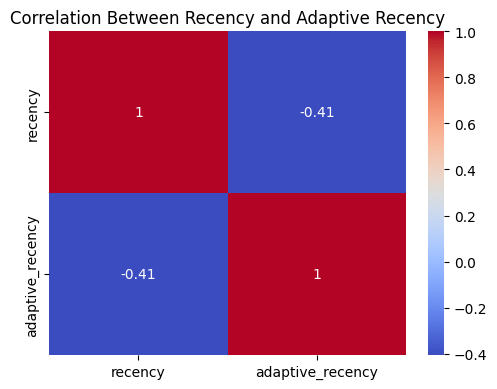

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = df[['recency', 'adaptive_recency']].corr()

plt.figure(figsize=(5,4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')

plt.title('Correlation Between Recency and Adaptive Recency')

plt.tight_layout()
plt.savefig('/kaggle/working/heatmap.png')
plt.show()

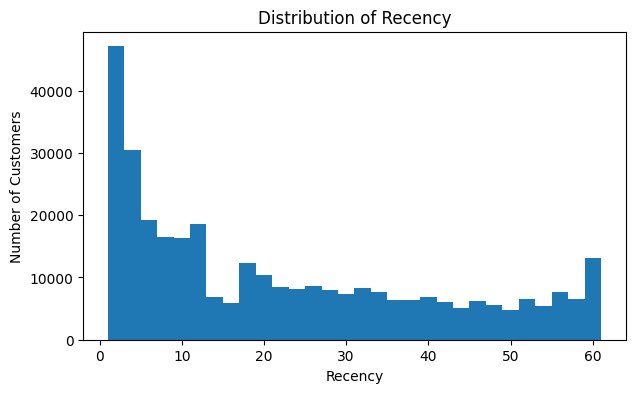

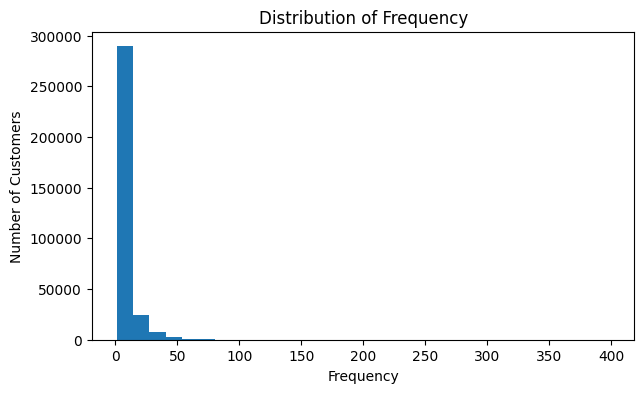

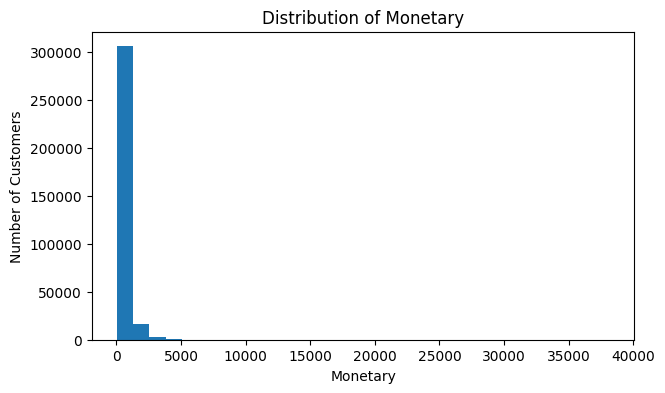

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# load file
df = pd.read_csv('/kaggle/working/final_selected_features.csv')

# ---------------- RECENCY HISTOGRAM ----------------
plt.figure(figsize=(7,4))
plt.hist(df['recency'], bins=30)
plt.xlabel('Recency')
plt.ylabel('Number of Customers')
plt.title('Distribution of Recency')
plt.show()

# ---------------- FREQUENCY HISTOGRAM ----------------
plt.figure(figsize=(7,4))
plt.hist(df['frequency'], bins=30)
plt.xlabel('Frequency')
plt.ylabel('Number of Customers')
plt.title('Distribution of Frequency')
plt.show()

# ---------------- MONETARY HISTOGRAM ----------------
plt.figure(figsize=(7,4))
plt.hist(df['monetary'], bins=30)
plt.xlabel('Monetary')
plt.ylabel('Number of Customers')
plt.title('Distribution of Monetary')
plt.show()

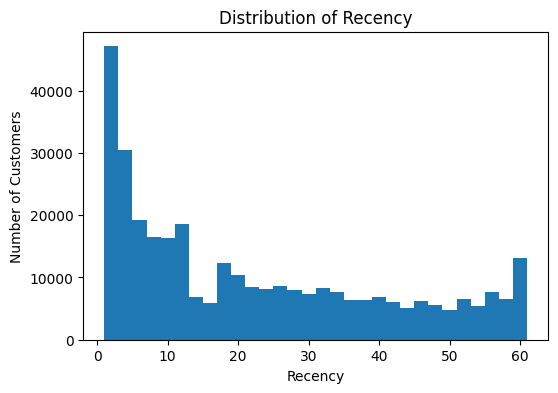

In [26]:
# RECENCY
plt.figure(figsize=(6,4))
plt.hist(df['recency'], bins=30)
plt.xlabel('Recency')
plt.ylabel('Number of Customers')
plt.title('Distribution of Recency')

plt.savefig('/kaggle/working/recency_histogram.png')
plt.show()

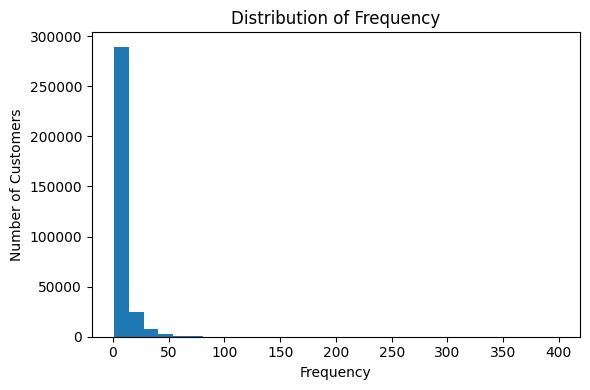

In [27]:
# FREQUENCY
plt.figure(figsize=(6,4))
plt.hist(df['frequency'], bins=30)
plt.xlabel('Frequency')
plt.ylabel('Number of Customers')
plt.title('Distribution of Frequency')
plt.tight_layout()


plt.savefig('/kaggle/working/frequency_histogram.png')
plt.show()

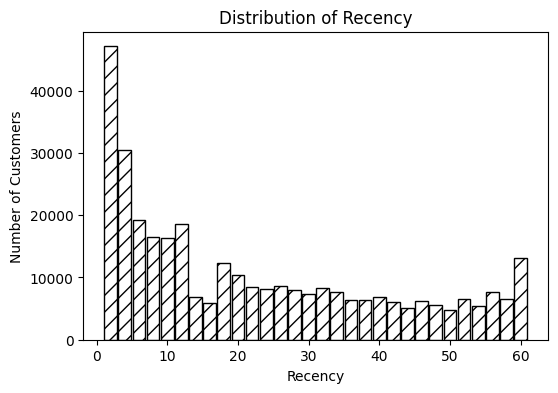

<Figure size 640x480 with 0 Axes>

In [58]:
plt.figure(figsize=(6,4))

n, bins, patches = plt.hist(
    df['recency'],
    bins=30,
    edgecolor='black',   # black border
    rwidth=0.9           # small gaps between bars
)

# hatch pattern on all bars
for patch in patches:
    patch.set_hatch('//')
    patch.set_facecolor('white')

plt.xlabel('Recency')
plt.ylabel('Number of Customers')
plt.title('Distribution of Recency')

plt.show()


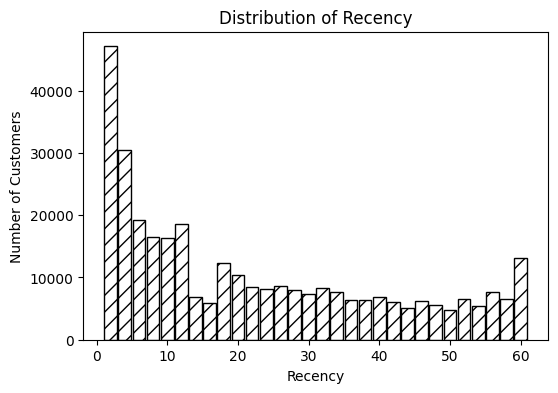

In [59]:
plt.figure(figsize=(6,4))

n, bins, patches = plt.hist(
    df['recency'],
    bins=30,
    edgecolor='black',
    rwidth=0.9
)

for patch in patches:
    patch.set_hatch('//')
    patch.set_facecolor('white')

plt.xlabel('Recency')
plt.ylabel('Number of Customers')
plt.title('Distribution of Recency')

# Save as PNG
plt.savefig(
    'recency_distribution.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

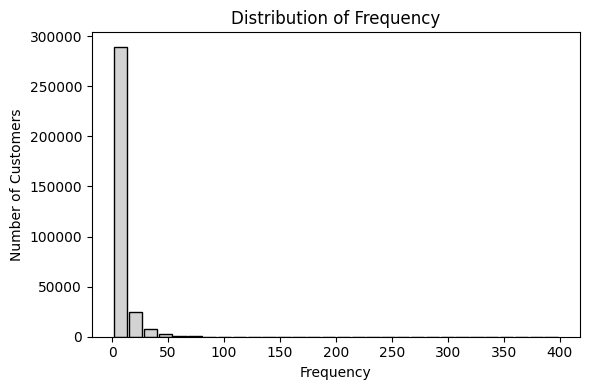

In [62]:
# FREQUENCY
plt.figure(figsize=(6,4))

plt.hist(
    df['frequency'],
    bins=30,
    color='lightgray',
    edgecolor='black',
    rwidth=0.9
)

plt.xlabel('Frequency')
plt.ylabel('Number of Customers')
plt.title('Distribution of Frequency')

plt.tight_layout()

plt.savefig(
    '/kaggle/working/frequency_histogram.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

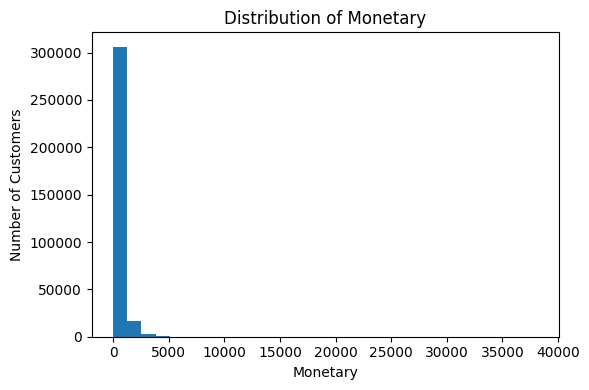

In [29]:
# MONETARY
plt.figure(figsize=(6,4))
plt.hist(df['monetary'], bins=30)
plt.xlabel('Monetary')
plt.ylabel('Number of Customers')
plt.title('Distribution of Monetary')
plt.tight_layout()

plt.savefig('/kaggle/working/monetary_histogram.png')
plt.show()

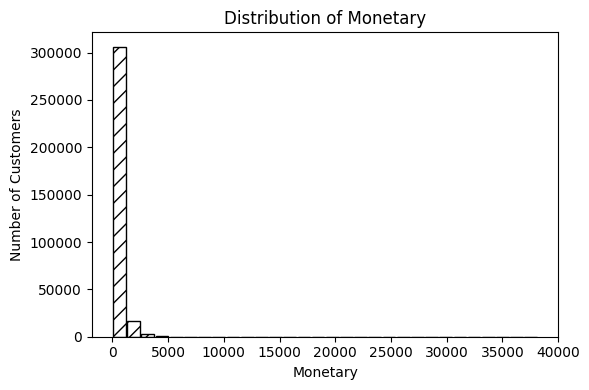

In [63]:
# MONETARY
plt.figure(figsize=(6,4))

n, bins, patches = plt.hist(
    df['monetary'],
    bins=30,
    edgecolor='black',
    rwidth=0.9
)

# Add hatch pattern
for patch in patches:
    patch.set_hatch('//')
    patch.set_facecolor('white')

plt.xlabel('Monetary')
plt.ylabel('Number of Customers')
plt.title('Distribution of Monetary')

plt.tight_layout()

plt.savefig(
    '/kaggle/working/monetary_histogram.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

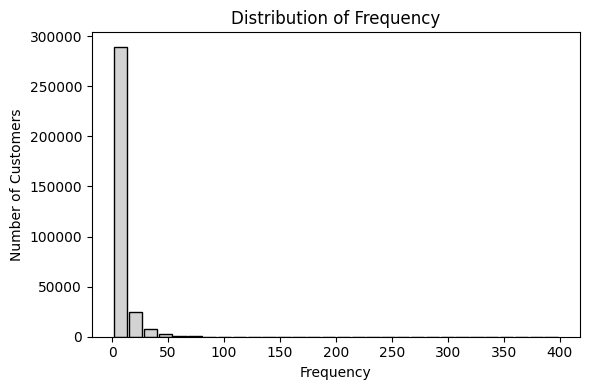

In [60]:
# FREQUENCY
plt.figure(figsize=(6,4))

plt.hist(
    df['frequency'],
    bins=30,
    color='lightgray',
    edgecolor='black',
    rwidth=0.9
)

plt.xlabel('Frequency')
plt.ylabel('Number of Customers')
plt.title('Distribution of Frequency')

plt.tight_layout()

plt.savefig(
    '/kaggle/working/frequency_histogram.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

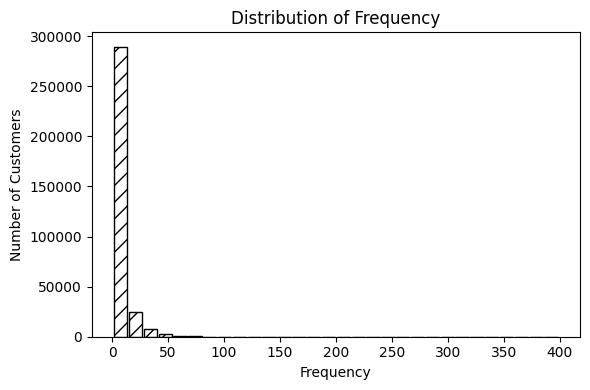

In [61]:
# FREQUENCY
plt.figure(figsize=(6,4))

n, bins, patches = plt.hist(
    df['frequency'],
    bins=30,
    edgecolor='black',
    rwidth=0.9
)

# Add hatch pattern
for patch in patches:
    patch.set_hatch('//')
    patch.set_facecolor('white')

plt.xlabel('Frequency')
plt.ylabel('Number of Customers')
plt.title('Distribution of Frequency')

plt.tight_layout()

plt.savefig(
    '/kaggle/working/frequency_histogram.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

In [30]:
import pandas as pd

# load file
df = pd.read_csv('/kaggle/working/final_selected_features.csv')

# check first few rows
print(df.head())

# check shape
print("Shape:", df.shape)

# check data types
print("\nData Types:")
print(df.dtypes)

# check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# check duplicate customer ids
print("\nDuplicate Customer IDs:", df['customer_id'].duplicated().sum())

# check zero values in important columns
columns_to_check = ['recency', 'adaptive_recency', 'frequency', 'monetary']

for col in columns_to_check:
    print(f"\nZero values in {col}: {(df[col] == 0).sum()}")

# check negative values
for col in columns_to_check:
    print(f"Negative values in {col}: {(df[col] < 0).sum()}")

# summary statistics
print("\nSummary Statistics:")
print(df[columns_to_check].describe())

# check unique values count
print("\nUnique Values:")
for col in columns_to_check:
    print(f"{col}: {df[col].nunique()}")

                                         customer_id  recency  \
0  00004f7040e477e00425c48b30bebf1d3a492a4712843e...       23   
1  00007e5d3053beab44473586a38210c51dbfe17feed8d0...       45   
2  0000c714dbf2ad84329b7b79fffcb4f1dd7ed8cce08c12...       27   
3  00011f09a34652c24b92f112682911c1df256f7d89a3fd...       24   
4  0001a900d4d4c7f5ba3769a5c6af5c55a850dc9970ed18...       60   

   adaptive_recency  frequency  monetary  
0          0.032789          1     143.7  
1          0.001247          1      92.5  
2          0.018096          1      34.1  
3          0.028261          1      40.5  
4          0.000134          1      38.5  
Shape: (326740, 5)

Data Types:
customer_id          object
recency               int64
adaptive_recency    float64
frequency             int64
monetary            float64
dtype: object

Missing Values:
customer_id         0
recency             0
adaptive_recency    0
frequency           0
monetary            0
dtype: int64

Duplicate Rows: 0

Dupli

In [31]:
features = ['recency', 'frequency', 'monetary', 'adaptive_recency']

# count exact duplicate rows
duplicate_count = df.duplicated(subset=features).sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 77523


In [32]:
# check skewness
print(df[['recency', 'adaptive_recency', 'frequency', 'monetary']].skew())

# check extreme values using percentiles
print(df[['recency', 'adaptive_recency', 'frequency', 'monetary']].quantile([0.90, 0.95, 0.99]))

recency             0.639387
adaptive_recency    2.094598
frequency           4.372872
monetary            5.866788
dtype: float64
      recency  adaptive_recency  frequency  monetary
0.90     53.0          0.342519       16.0   971.405
0.95     57.0          0.481087       25.0  1441.150
0.99     61.0          0.739097       47.0  2720.541


K-means


kmeans++ on RFM


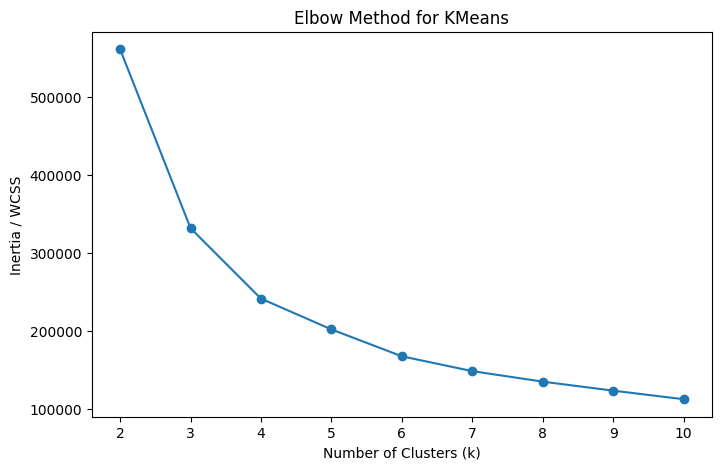

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# features
features = ['recency', 'frequency', 'monetary']

# keep only needed columns
df_kmeans = df[features].dropna().copy()

# scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_kmeans)

# elbow method
inertia_values = []
K_range = range(2, 11)   # 2 se 10 clusters check kar rahe hain

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# plot elbow curve
plt.figure(figsize=(8,5))
plt.plot(K_range, inertia_values, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia / WCSS')
plt.title('Elbow Method for KMeans')
plt.show()

In [34]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
import numpy as np
features = ['recency', 'frequency', 'monetary']

# keep only needed columns and drop missing values
df_kmeans = df[features].dropna().copy()

print("Shape of data used for clustering:", df_kmeans.shape)

# -----------------------------
# 2. Scale the data
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_kmeans)

# -----------------------------
# 3. Apply KMeans++
# -----------------------------
kmeans_pp = KMeans(
    n_clusters=4,
    init='k-means++',   # explicit KMeans++
    n_init=10,
    random_state=42
) 



df_kmeans['cluster_kmeans_pp'] = kmeans_pp.fit_predict(X_scaled)

# -----------------------------
# 4. Cluster counts
# -----------------------------
print("\nCluster Counts:")
print(df_kmeans['cluster_kmeans_pp'].value_counts().sort_index())

# -----------------------------
# 5. Cluster summary
# -----------------------------
cluster_summary = df_kmeans.groupby('cluster_kmeans_pp')[features].mean()

print("\nCluster Summary:")
print(cluster_summary)


Shape of data used for clustering: (326740, 3)

Cluster Counts:
cluster_kmeans_pp
0     46089
1    109741
2      9607
3    161303
Name: count, dtype: int64

Cluster Summary:
                     recency  frequency     monetary
cluster_kmeans_pp                                   
0                   5.598386  17.542906  1044.439175
1                  44.929826   1.919520   135.331315
2                   3.314458  44.802436  2591.409833
3                  11.798330   3.381766   211.588346


In [35]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.utils import resample

# labels from your clustering
labels = df_kmeans['cluster_kmeans_pp'].values

# -----------------------------
# Silhouette Score on sample only
# -----------------------------
X_sample, labels_sample = resample(
    X_scaled,
    labels,
    n_samples=20000,
    random_state=42,
    stratify=labels
)

silhouette = silhouette_score(X_sample, labels_sample)

# -----------------------------
# CH and DB on full data
# -----------------------------
calinski = calinski_harabasz_score(X_scaled, labels)
davies = davies_bouldin_score(X_scaled, labels)

print("KMeans++ Evaluation Metrics")
print("Silhouette Score (sample = 20,000):", silhouette)
print("Calinski-Harabasz Score (full data):", calinski)
print("Davies-Bouldin Score (full data):", davies)

KMeans++ Evaluation Metrics
Silhouette Score (sample = 20,000): 0.5036003267454339
Calinski-Harabasz Score (full data): 333622.55444201437
Davies-Bouldin Score (full data): 0.7539000622096551


kmeans ++ on RFMA

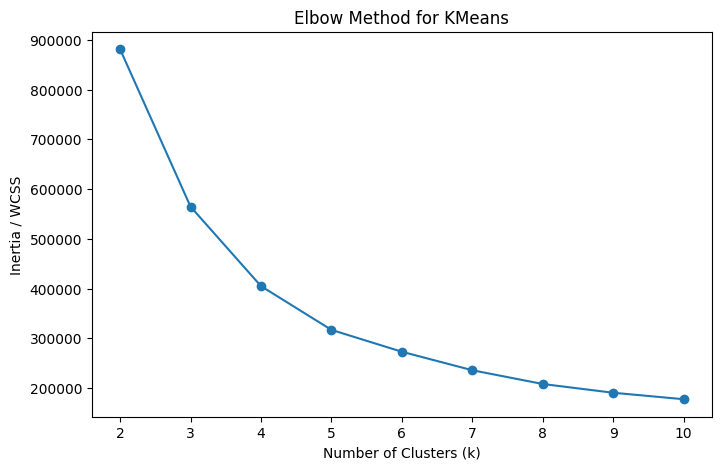

In [36]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# features
features = ['recency', 'adaptive_recency', 'frequency', 'monetary']

# keep only needed columns
df_kmeans = df[features].dropna().copy()

# scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_kmeans)

# elbow method
inertia_values = []
K_range = range(2, 11)   # 2 se 10 clusters check kar rahe hain

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# plot elbow curve
plt.figure(figsize=(8,5))
plt.plot(K_range, inertia_values, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia / WCSS')
plt.title('Elbow Method for KMeans')
plt.show()

In [37]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
import numpy as np
features = ['recency', 'frequency','adaptive_recency' ,'monetary']

# keep only needed columns and drop missing values
df_kmeans = df[features].dropna().copy()

print("Shape of data used for clustering:", df_kmeans.shape)

# -----------------------------
# 2. Scale the data
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_kmeans)

# -----------------------------
# 3. Apply KMeans++
# -----------------------------
kmeans_pp = KMeans(
    n_clusters=4,
    init='k-means++',   # explicit KMeans++
    n_init=10,
    random_state=42
) 



df_kmeans['cluster_kmeans_pp'] = kmeans_pp.fit_predict(X_scaled)

# -----------------------------
# 4. Cluster counts
# -----------------------------
print("\nCluster Counts:")
print(df_kmeans['cluster_kmeans_pp'].value_counts().sort_index())

# -----------------------------
# 5. Cluster summary
# -----------------------------
cluster_summary = df_kmeans.groupby('cluster_kmeans_pp')[features].mean()

print("\nCluster Summary:")
print(cluster_summary)


Shape of data used for clustering: (326740, 4)

Cluster Counts:
cluster_kmeans_pp
0     47988
1    117497
2    132781
3     28474
Name: count, dtype: int64

Cluster Summary:
                     recency  frequency  adaptive_recency     monetary
cluster_kmeans_pp                                                     
0                   8.592961   3.419292          0.445237   231.256409
1                  43.705141   1.930007          0.007035   135.319316
2                  10.959384   5.509621          0.080290   335.009310
3                   4.243731  30.647714          0.023550  1774.743371


In [38]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.utils import resample

# labels from your clustering
labels = df_kmeans['cluster_kmeans_pp'].values

# -----------------------------
# Silhouette Score on sample only
# -----------------------------
X_sample, labels_sample = resample(
    X_scaled,
    labels,
    n_samples=20000,
    random_state=42,
    stratify=labels
)

silhouette = silhouette_score(X_sample, labels_sample)

# -----------------------------
# CH and DB on full data
# -----------------------------
calinski = calinski_harabasz_score(X_scaled, labels)
davies = davies_bouldin_score(X_scaled, labels)

print("KMeans++ Evaluation Metrics")
print("Silhouette Score (sample = 20,000):", silhouette)
print("Calinski-Harabasz Score (full data):", calinski)
print("Davies-Bouldin Score (full data):", davies)

KMeans++ Evaluation Metrics
Silhouette Score (sample = 20,000): 0.4206869384448449
Calinski-Harabasz Score (full data): 242682.5376840401
Davies-Bouldin Score (full data): 0.8211668618093217


kmeans on RFMA

In [39]:
import pandas as pd

# load final file
df_final = pd.read_csv('/kaggle/working/final_selected_features.csv')

print("df_final columns:", df_final.columns)
print("df_kmeans columns:", df_kmeans.columns)

# IMPORTANT: check rows are same
print("df_final shape:", df_final.shape)
print("df_kmeans shape:", df_kmeans.shape)

# attach customer_id from df_final to kmeans labels
df_labels = df_final[['customer_id']].copy()
df_labels['cluster_kmeans'] = df_kmeans['cluster_kmeans_pp'].values

# merge back with final features
df_merged = df_final.merge(
    df_labels,
    on='customer_id',
    how='left'
)

print(df_merged.head())
print("\nMissing labels:", df_merged['cluster_kmeans'].isnull().sum())
print(df_merged['cluster_kmeans'].value_counts())

# save
df_merged.to_csv('/kaggle/working/final_with_labels.csv', index=False)

print("✅ Done! File saved as final_with_labels.csv")

df_final columns: Index(['customer_id', 'recency', 'adaptive_recency', 'frequency', 'monetary'], dtype='object')
df_kmeans columns: Index(['recency', 'frequency', 'adaptive_recency', 'monetary',
       'cluster_kmeans_pp'],
      dtype='object')
df_final shape: (326740, 5)
df_kmeans shape: (326740, 5)
                                         customer_id  recency  \
0  00004f7040e477e00425c48b30bebf1d3a492a4712843e...       23   
1  00007e5d3053beab44473586a38210c51dbfe17feed8d0...       45   
2  0000c714dbf2ad84329b7b79fffcb4f1dd7ed8cce08c12...       27   
3  00011f09a34652c24b92f112682911c1df256f7d89a3fd...       24   
4  0001a900d4d4c7f5ba3769a5c6af5c55a850dc9970ed18...       60   

   adaptive_recency  frequency  monetary  cluster_kmeans  
0          0.032789          1     143.7               2  
1          0.001247          1      92.5               1  
2          0.018096          1      34.1               1  
3          0.028261          1      40.5               2  
4          

In [40]:
# original file jisme ID hai
df_original = pd.read_csv('/kaggle/input/datasets/komalwahid/finaldata2/final_cleaned (1).csv')

# sirf ID le lo
df_kmeans['customer_id'] = df_original['customer_id']

FCA - FCAPY

In [41]:
import pandas as pd
import numpy as np

df = pd.read_csv("/kaggle/working/final_with_labels.csv")

# required columns
required = ["customer_id", "recency", "frequency", "monetary", "cluster_kmeans"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# -----------------------------
# 1. Make RFM scores if not already present
# -----------------------------
def quintile_score(s, ascending=True):
    ranks = s.rank(method="first", na_option="keep")
    labels = [1, 2, 3, 4, 5] if ascending else [5, 4, 3, 2, 1]
    return pd.qcut(ranks, q=5, labels=labels, duplicates="drop").astype("Int8")

if "R_score" not in df.columns:
    df["R_score"] = quintile_score(df["recency"], ascending=False)

if "F_score" not in df.columns:
    df["F_score"] = quintile_score(df["frequency"], ascending=True)

if "M_score" not in df.columns:
    df["M_score"] = quintile_score(df["monetary"], ascending=True)

# -----------------------------
# 2. Create FCA attributes
# -----------------------------
df["cluster_attr"] = "Cluster_" + df["cluster_kmeans"].astype(str)
df["R_attr"] = "R" + df["R_score"].astype(str)
df["F_attr"] = "F" + df["F_score"].astype(str)
df["M_attr"] = "M" + df["M_score"].astype(str)

# -----------------------------
# 3. Make binary FCA context
# rows = customers
# columns = Cluster + RFM attributes
# -----------------------------
attr_cols = ["cluster_attr", "R_attr", "F_attr", "M_attr"]

all_attrs = sorted(
    pd.unique(df[attr_cols].values.ravel())
)

context = pd.DataFrame(False, index=df["customer_id"], columns=all_attrs)

for col in attr_cols:
    temp = pd.crosstab(df["customer_id"], df[col]).astype(bool)
    context.update(temp)

context = context.astype(bool)

print("FCA context shape:", context.shape)
print(context.head())

# -----------------------------
# 4. FCA-style implication:
# Cluster_X -> common R/F/M attributes
# -----------------------------
results = []

cluster_attrs = sorted(df["cluster_attr"].unique())

for c in cluster_attrs:
    cluster_customers = context[context[c] == True]
    cluster_size = len(cluster_customers)

    for attr in context.columns:
        if attr.startswith("Cluster_"):
            continue

        support_count = cluster_customers[attr].sum()
        confidence = support_count / cluster_size if cluster_size > 0 else 0

        results.append({
            "cluster": c,
            "attribute": attr,
            "cluster_size": cluster_size,
            "support_count": int(support_count),
            "confidence": confidence
        })

rules = pd.DataFrame(results)

# keep strong explanations only
strong_rules = rules[rules["confidence"] >= 0.50].copy()
strong_rules = strong_rules.sort_values(
    ["cluster", "confidence", "support_count"],
    ascending=[True, False, False]
)

print("Strong FCA explanations:")
print(strong_rules)

strong_rules.to_csv("/kaggle/working/fca_cluster_explanations.csv", index=False)

# -----------------------------
# 5. Create readable explanation per cluster
# -----------------------------
explanations = []

for c in cluster_attrs:
    temp = strong_rules[strong_rules["cluster"] == c]

    attrs = temp["attribute"].tolist()
    confs = temp["confidence"].round(2).tolist()

    explanation = ", ".join(
        [f"{a} ({conf*100:.0f}%)" for a, conf in zip(attrs, confs)]
    )

    explanations.append({
        "cluster": c,
        "explanation": explanation
    })

explanation_df = pd.DataFrame(explanations)

print(explanation_df)

explanation_df.to_csv(
    "/kaggle/working/readable_fca_cluster_explanations.csv",
    index=False
)

FCA context shape: (326740, 19)
                                                    Cluster_0  Cluster_1  \
customer_id                                                                
00004f7040e477e00425c48b30bebf1d3a492a4712843e3...      False      False   
00007e5d3053beab44473586a38210c51dbfe17feed8d0e...      False       True   
0000c714dbf2ad84329b7b79fffcb4f1dd7ed8cce08c12a...      False       True   
00011f09a34652c24b92f112682911c1df256f7d89a3fdb...      False      False   
0001a900d4d4c7f5ba3769a5c6af5c55a850dc9970ed18a...      False       True   

                                                    Cluster_2  Cluster_3  \
customer_id                                                                
00004f7040e477e00425c48b30bebf1d3a492a4712843e3...       True      False   
00007e5d3053beab44473586a38210c51dbfe17feed8d0e...      False      False   
0000c714dbf2ad84329b7b79fffcb4f1dd7ed8cce08c12a...      False      False   
00011f09a34652c24b92f112682911c1df256f7d89a3fdb...     

In [42]:
# -----------------------------
# Show ALL FCA-style rules
# Cluster_X -> attribute
# -----------------------------

all_rules = rules.copy()

all_rules = all_rules.sort_values(
    ["cluster", "confidence", "support_count"],
    ascending=[True, False, False]
)

print("Total rules:", len(all_rules))
print(all_rules.head(100))

# full file save
all_rules.to_csv("/kaggle/working/all_fca_rules.csv", index=False)

print("✅ All rules saved at: /kaggle/working/all_fca_rules.csv")

Total rules: 60
      cluster attribute  cluster_size  support_count  confidence
13  Cluster_0        R4         47988          25206    0.525256
3   Cluster_0        F4         47988          18012    0.375344
2   Cluster_0        F3         47988          16644    0.346837
8   Cluster_0        M4         47988          14769    0.307764
7   Cluster_0        M3         47988          14096    0.293740
12  Cluster_0        R3         47988          10664    0.222222
14  Cluster_0        R5         47988          10367    0.216033
6   Cluster_0        M2         47988          10032    0.209052
1   Cluster_0        F2         47988           6775    0.141181
5   Cluster_0        M1         47988           5615    0.117008
0   Cluster_0        F1         47988           4973    0.103630
9   Cluster_0        M5         47988           3476    0.072435
11  Cluster_0        R2         47988           1751    0.036488
4   Cluster_0        F5         47988           1584    0.033008
10  Clust

In [43]:
rules_filtered = rules[rules["confidence"] >= 0.5].copy()

In [44]:
def select_best_rules(cluster_df):
    selected = []
    
    for prefix in ["R", "F", "M"]:
        temp = cluster_df[cluster_df["attribute"].str.startswith(prefix)]
        
        if not temp.empty:
            best = temp.sort_values("confidence", ascending=False).iloc[0]
            selected.append(best)
    
    return pd.DataFrame(selected)

In [45]:
final_rules = (
    rules_filtered
    .groupby("cluster", group_keys=False)
    .apply(select_best_rules)
)

final_rules = final_rules.sort_values(["cluster", "attribute"])

print(final_rules)

      cluster attribute  cluster_size  support_count  confidence
13  Cluster_0        R4         47988          25206    0.525256
25  Cluster_1        R1        117497          65255    0.555376
49  Cluster_3        F5         28474          28373    0.996453
54  Cluster_3        M5         28474          28302    0.993959
59  Cluster_3        R5         28474          20101    0.705942


/tmp/ipykernel_57/2786804492.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(select_best_rules)


In [46]:
rules_filtered = rules[rules["confidence"] >= 0.3].copy()

In [47]:
def select_best_rules(cluster_df):
    selected = []
    
    for prefix in ["R", "F", "M"]:
        temp = cluster_df[cluster_df["attribute"].str.startswith(prefix)]
        
        if not temp.empty:
            best = temp.sort_values("confidence", ascending=False).iloc[0]
            selected.append(best)
    
    return pd.DataFrame(selected)

In [48]:
final_rules = (
    rules_filtered
    .groupby("cluster", group_keys=False)
    .apply(select_best_rules)
)

final_rules = final_rules.sort_values(["cluster", "attribute"])

print(final_rules)

      cluster attribute  cluster_size  support_count  confidence
3   Cluster_0        F4         47988          18012    0.375344
8   Cluster_0        M4         47988          14769    0.307764
13  Cluster_0        R4         47988          25206    0.525256
15  Cluster_1        F1        117497          39022    0.332111
20  Cluster_1        M1        117497          38503    0.327693
25  Cluster_1        R1        117497          65255    0.555376
42  Cluster_2        R3        132781          53062    0.399620
49  Cluster_3        F5         28474          28373    0.996453
54  Cluster_3        M5         28474          28302    0.993959
59  Cluster_3        R5         28474          20101    0.705942


/tmp/ipykernel_57/2786804492.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(select_best_rules)


In [49]:
rules_filtered = rules[rules["confidence"] >= 0.2].copy()

In [50]:
def select_best_rules(cluster_df):
    selected = []
    
    for prefix in ["R", "F", "M"]:
        temp = cluster_df[cluster_df["attribute"].str.startswith(prefix)]
        
        if not temp.empty:
            best = temp.sort_values("confidence", ascending=False).iloc[0]
            selected.append(best)
    
    return pd.DataFrame(selected)

In [51]:
final_rules = (
    rules_filtered
    .groupby("cluster", group_keys=False)
    .apply(select_best_rules)
)

final_rules = final_rules.sort_values(["cluster", "attribute"])

print(final_rules)

      cluster attribute  cluster_size  support_count  confidence
3   Cluster_0        F4         47988          18012    0.375344
8   Cluster_0        M4         47988          14769    0.307764
13  Cluster_0        R4         47988          25206    0.525256
15  Cluster_1        F1        117497          39022    0.332111
20  Cluster_1        M1        117497          38503    0.327693
25  Cluster_1        R1        117497          65255    0.555376
34  Cluster_2        F5        132781          33737    0.254080
38  Cluster_2        M4        132781          35461    0.267064
42  Cluster_2        R3        132781          53062    0.399620
49  Cluster_3        F5         28474          28373    0.996453
54  Cluster_3        M5         28474          28302    0.993959
59  Cluster_3        R5         28474          20101    0.705942


/tmp/ipykernel_57/2786804492.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(select_best_rules)


In [52]:
# =========================================================
# Cluster-level FCA Concept Lattice Diagram
# =========================================================

!pip install concepts graphviz -q

import pandas as pd
from concepts import Context
from graphviz import Digraph

# -----------------------------
# 1. Use your explained rules
# -----------------------------
rules_data = [
    ["Cluster_0", "F4"],
    ["Cluster_0", "M4"],
    ["Cluster_0", "R4"],

    ["Cluster_1", "F1"],
    ["Cluster_1", "M1"],
    ["Cluster_1", "R1"],

    ["Cluster_2", "R3"],
    ["Cluster_2", "M4"],
    ["Cluster_2", "F5"],

    ["Cluster_3", "F5"],
    ["Cluster_3", "M5"],
    ["Cluster_3", "R5"],
]

rules_df = pd.DataFrame(rules_data, columns=["cluster", "attribute"])

print(rules_df)

      cluster attribute
0   Cluster_0        F4
1   Cluster_0        M4
2   Cluster_0        R4
3   Cluster_1        F1
4   Cluster_1        M1
5   Cluster_1        R1
6   Cluster_2        R3
7   Cluster_2        M4
8   Cluster_2        F5
9   Cluster_3        F5
10  Cluster_3        M5
11  Cluster_3        R5


In [53]:
# -----------------------------
# 2. Create FCA binary context
# -----------------------------
objects = sorted(rules_df["cluster"].unique())
attributes = sorted(rules_df["attribute"].unique())

binary_context = pd.DataFrame(False, index=objects, columns=attributes)

for _, row in rules_df.iterrows():
    binary_context.loc[row["cluster"], row["attribute"]] = True

print(binary_context)

binary_context.to_csv("/kaggle/working/cluster_level_fca_context.csv")

              F1     F4     F5     M1     M4     M5     R1     R3     R4  \
Cluster_0  False   True  False  False   True  False  False  False   True   
Cluster_1   True  False  False   True  False  False   True  False  False   
Cluster_2  False  False   True  False   True  False  False   True  False   
Cluster_3  False  False   True  False  False   True  False  False  False   

              R5  
Cluster_0  False  
Cluster_1  False  
Cluster_2  False  
Cluster_3   True  


In [54]:
# -----------------------------
# 2. Create FCA binary context
# -----------------------------
objects = sorted(rules_df["cluster"].unique())
attributes = sorted(rules_df["attribute"].unique())

binary_context = pd.DataFrame(False, index=objects, columns=attributes)

for _, row in rules_df.iterrows():
    binary_context.loc[row["cluster"], row["attribute"]] = True

print(binary_context)

binary_context.to_csv("/kaggle/working/cluster_level_fca_context.csv")

              F1     F4     F5     M1     M4     M5     R1     R3     R4  \
Cluster_0  False   True  False  False   True  False  False  False   True   
Cluster_1   True  False  False   True  False  False   True  False  False   
Cluster_2  False  False   True  False   True  False  False   True  False   
Cluster_3  False  False   True  False  False   True  False  False  False   

              R5  
Cluster_0  False  
Cluster_1  False  
Cluster_2  False  
Cluster_3   True  


In [55]:
# -----------------------------
# 3. Create Formal Context
# -----------------------------
context = Context(
    objects,
    attributes,
    binary_context.values.tolist()
)

print(context)

<Context object mapping 4 objects to 10 properties [5a702e2c] at 0x788a1c2a4890>
             |F1|F4|F5|M1|M4|M5|R1|R3|R4|R5|
    Cluster_0|  |X |  |  |X |  |  |  |X |  |
    Cluster_1|X |  |  |X |  |  |X |  |  |  |
    Cluster_2|  |  |X |  |X |  |  |X |  |  |
    Cluster_3|  |  |X |  |  |X |  |  |  |X |


In [56]:
# -----------------------------
# 4. Generate concept lattice
# -----------------------------
lattice = context.lattice

print("Number of concepts:", len(lattice))

for i, concept in enumerate(lattice):
    print(f"\nConcept {i}")
    print("Extent / Objects:", list(concept.extent))
    print("Intent / Attributes:", list(concept.intent))

Number of concepts: 8

Concept 0
Extent / Objects: []
Intent / Attributes: ['F1', 'F4', 'F5', 'M1', 'M4', 'M5', 'R1', 'R3', 'R4', 'R5']

Concept 1
Extent / Objects: ['Cluster_0']
Intent / Attributes: ['F4', 'M4', 'R4']

Concept 2
Extent / Objects: ['Cluster_1']
Intent / Attributes: ['F1', 'M1', 'R1']

Concept 3
Extent / Objects: ['Cluster_2']
Intent / Attributes: ['F5', 'M4', 'R3']

Concept 4
Extent / Objects: ['Cluster_3']
Intent / Attributes: ['F5', 'M5', 'R5']

Concept 5
Extent / Objects: ['Cluster_0', 'Cluster_2']
Intent / Attributes: ['M4']

Concept 6
Extent / Objects: ['Cluster_2', 'Cluster_3']
Intent / Attributes: ['F5']

Concept 7
Extent / Objects: ['Cluster_0', 'Cluster_1', 'Cluster_2', 'Cluster_3']
Intent / Attributes: []


In [57]:
# -----------------------------
# 5. Draw lattice manually using Graphviz
# -----------------------------
dot = Digraph(comment="Cluster Level FCA Concept Lattice")
dot.attr(rankdir="BT")   # bottom to top

concept_ids = {}

for i, concept in enumerate(lattice):
    extent = ", ".join(concept.extent) if concept.extent else "∅"
    intent = ", ".join(concept.intent) if concept.intent else "∅"
    
    label = f"Objects: {extent}\nAttributes: {intent}"
    node_id = f"C{i}"
    concept_ids[concept] = node_id
    
    dot.node(node_id, label=label, shape="box")

# add edges between concepts
for parent, child in lattice.graph:
    dot.edge(concept_ids[parent], concept_ids[child])

# save diagram
output_path = "/kaggle/working/cluster_level_fca_lattice"

dot.render(output_path, format="png", cleanup=True)
dot.render(output_path, format="pdf", cleanup=True)

print("✅ PNG saved at:", output_path + ".png")
print("✅ PDF saved at:", output_path + ".pdf")

AttributeError: 'Lattice' object has no attribute 'graph'

In [ ]:
# -----------------------------
# 5. Draw lattice using concept.upper_neighbors / lower_neighbors
# -----------------------------
from graphviz import Digraph

dot = Digraph(comment="Cluster Level FCA Concept Lattice")
dot.attr(rankdir="BT")

concept_ids = {}

# create nodes
for i, concept in enumerate(lattice):
    extent = ", ".join(concept.extent) if concept.extent else "∅"
    intent = ", ".join(concept.intent) if concept.intent else "∅"
    
    label = f"Objects: {extent}\nAttributes: {intent}"
    node_id = f"C{i}"
    
    concept_ids[concept] = node_id
    dot.node(node_id, label=label, shape="box")

# create edges
for concept in lattice:
    for upper in concept.upper_neighbors:
        dot.edge(concept_ids[concept], concept_ids[upper])

# save diagram
output_path = "/kaggle/working/cluster_level_fca_lattice"

dot.render(output_path, format="png", cleanup=True)
dot.render(output_path, format="pdf", cleanup=True)

print("✅ PNG saved at:", output_path + ".png")
print("✅ PDF saved at:", output_path + ".pdf")

In [ ]:
from sklearn.metrics import silhouette_score
import numpy as np

# sample size
sample_size = 50000

# random sample indices
np.random.seed(42)
sample_idx = np.random.choice(X_scaled.shape[0], sample_size, replace=False)

# sampled data
X_sample = X_scaled[sample_idx]
labels_sample = df_kmeans['cluster_kmeans'].to_numpy()[sample_idx]

# silhouette score
sil_score = silhouette_score(X_sample, labels_sample)

print("Sample Silhouette Score:", sil_score)

In [ ]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

ch_score = calinski_harabasz_score(X_scaled, df_kmeans['cluster_kmeans'])
db_score = davies_bouldin_score(X_scaled, df_kmeans['cluster_kmeans'])

print("Calinski-Harabasz Score:", ch_score)
print("Davies-Bouldin Score:", db_score)

K-means++


In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
import numpy as np
features = ['recency', 'adaptive_recency', 'frequency', 'monetary']

# keep only needed columns and drop missing values
df_kmeans = df[features].dropna().copy()

print("Shape of data used for clustering:", df_kmeans.shape)

# -----------------------------
# 2. Scale the data
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_kmeans)

# -----------------------------
# 3. Apply KMeans++
# -----------------------------
kmeans_pp = KMeans(
    n_clusters=4,
    init='k-means++',   # explicit KMeans++
    n_init=10,
    random_state=42
) 



df_kmeans['cluster_kmeans_pp'] = kmeans_pp.fit_predict(X_scaled)

# -----------------------------
# 4. Cluster counts
# -----------------------------
print("\nCluster Counts:")
print(df_kmeans['cluster_kmeans_pp'].value_counts().sort_index())

# -----------------------------
# 5. Cluster summary
# -----------------------------
cluster_summary = df_kmeans.groupby('cluster_kmeans_pp')[features].mean()

print("\nCluster Summary:")
print(cluster_summary)


In [ ]:
from sklearn.metrics import silhouette_score
import numpy as np

# sample size
sample_size = 50000

# random sample
np.random.seed(42)
sample_idx = np.random.choice(X_scaled.shape[0], sample_size, replace=False)

# sample data and labels
X_sample = X_scaled[sample_idx]
labels_sample = df_kmeans['cluster_kmeans_pp'].to_numpy()[sample_idx]

# silhouette score on sample
sil_score = silhouette_score(X_sample, labels_sample)

print("Sample Silhouette Score:", sil_score)

In [ ]:
ch_score = calinski_harabasz_score(X_scaled, df_kmeans['cluster_kmeans_pp'])
db_score = davies_bouldin_score(X_scaled, df_kmeans['cluster_kmeans_pp'])

print("\nCalinski-Harabasz Score:", ch_score)
print("Davies-Bouldin Score:", db_score)


BIRCH

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import Birch
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
import numpy as np

# -----------------------------
# 1. Select features
# -----------------------------
features = ['recency', 'adaptive_recency', 'frequency', 'monetary']

# keep only needed columns and drop missing values
df_birch = df[features].dropna().copy()

print("Shape of data used for clustering:", df_birch.shape)

# -----------------------------
# 2. Scale the data
# -----------------------------
scaler = StandardScaler()
X_scaled_birch = scaler.fit_transform(df_birch)

# -----------------------------
# 3. Apply BIRCH
# -----------------------------
birch_model = Birch(
    n_clusters=4,      # final number of clusters
    threshold=0.5,     # can tune later
    branching_factor=50
)

df_birch['cluster_birch'] = birch_model.fit_predict(X_scaled_birch)

# -----------------------------
# 4. Cluster counts
# -----------------------------
print("\nCluster Counts:")
print(df_birch['cluster_birch'].value_counts().sort_index())

# -----------------------------
# 5. Cluster summary
# -----------------------------
cluster_summary = df_birch.groupby('cluster_birch')[features].mean()

print("\nCluster Summary:")
print(cluster_summary)

# -----------------------------
# 6. Evaluation metrics
# -----------------------------
ch_score = calinski_harabasz_score(X_scaled_birch, df_birch['cluster_birch'])
db_score = davies_bouldin_score(X_scaled_birch, df_birch['cluster_birch'])

print("\nCalinski-Harabasz Score:", ch_score)
print("Davies-Bouldin Score:", db_score)

# -----------------------------
# 7. Sample-based silhouette score
# -----------------------------
sample_size = 50000

np.random.seed(42)
sample_idx = np.random.choice(X_scaled_birch.shape[0], sample_size, replace=False)

X_sample = X_scaled_birch[sample_idx]
labels_sample = df_birch['cluster_birch'].to_numpy()[sample_idx]

sil_score = silhouette_score(X_sample, labels_sample)

print("Sample Silhouette Score:", sil_score)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import Birch
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
import pandas as pd
import numpy as np

# -----------------------------
# 1. Select features
# -----------------------------
features = ['recency', 'adaptive_recency', 'frequency', 'monetary']

df_birch = df[features].dropna().copy()
print("Shape of data used:", df_birch.shape)

# -----------------------------
# 2. Scale data
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_birch)

# -----------------------------
# 3. Sample for silhouette
# -----------------------------
sample_size = min(50000, X_scaled.shape[0])

np.random.seed(42)
sample_idx = np.random.choice(X_scaled.shape[0], sample_size, replace=False)

X_sample = X_scaled[sample_idx]

# -----------------------------
# 4. Try different BIRCH thresholds
# -----------------------------
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5]

results = []

for th in thresholds:
    print(f"\nRunning BIRCH with threshold = {th}")

    birch_model = Birch(
        n_clusters=4,
        threshold=th,
        branching_factor=50
    )

    labels = birch_model.fit_predict(X_scaled)

    # avoid error if only 1 cluster is created
    n_unique = len(np.unique(labels))
    print("Unique clusters:", n_unique)

    if n_unique < 2:
        print("Skipped because only one cluster formed.")
        continue

    labels_sample = labels[sample_idx]

    ch = calinski_harabasz_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    sil = silhouette_score(X_sample, labels_sample)

    results.append({
        'threshold': th,
        'n_clusters': n_unique,
        'silhouette': sil,
        'calinski_harabasz': ch,
        'davies_bouldin': db
    })

# -----------------------------
# 5. Results comparison
# -----------------------------
results_df = pd.DataFrame(results)

print("\nBIRCH Threshold Comparison:")
print(results_df.sort_values(by='silhouette', ascending=False))

# -----------------------------
# 6. Pick best threshold
# -----------------------------
best_threshold = results_df.sort_values(
    by=['silhouette', 'davies_bouldin'],
    ascending=[False, True]
).iloc[0]['threshold']

print("\nBest Threshold Selected:", best_threshold)

# -----------------------------
# 7. Final BIRCH with best threshold
# -----------------------------
final_birch = Birch(
    n_clusters=4,
    threshold=best_threshold,
    branching_factor=50
)

df_birch['cluster_birch'] = final_birch.fit_predict(X_scaled)

# -----------------------------
# 8. Cluster counts
# -----------------------------
print("\nFinal Cluster Counts:")
print(df_birch['cluster_birch'].value_counts().sort_index())

# -----------------------------
# 9. Cluster summary
# -----------------------------
cluster_summary = df_birch.groupby('cluster_birch')[features].mean()

print("\nFinal Cluster Summary:")
print(cluster_summary)

# -----------------------------
# 10. Final evaluation
# -----------------------------
final_labels = df_birch['cluster_birch'].to_numpy()
final_labels_sample = final_labels[sample_idx]

ch_score = calinski_harabasz_score(X_scaled, final_labels)
db_score = davies_bouldin_score(X_scaled, final_labels)
sil_score = silhouette_score(X_sample, final_labels_sample)

print("\nFinal Calinski-Harabasz Score:", ch_score)
print("Final Davies-Bouldin Score:", db_score)
print("Final Sample Silhouette Score:", sil_score)

# -----------------------------
# 11. Save file
# -----------------------------
df_birch.to_csv('/kaggle/working/birch_clustered_file.csv', index=False)

print("\nSaved: /kaggle/working/birch_clustered_file.csv")

### import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# =========================================================
# 1) LOAD FILE
# =========================================================
df = pd.read_csv("/kaggle/input/datasets/komalwahid/finaldata2/final_cleaned (1).csv")

# =========================================================
# 2) SELECT FEATURES
# =========================================================
features = [
    "recency",
    "adaptive_recency",
    "frequency",
    "monetary"
]

# =========================================================
# 3) CLEAN DATA
# =========================================================
X = df[features].copy()

print("Initial Shape:", X.shape)

print("\nNull values:")
print(X.isnull().sum())

# fill missing
X = X.fillna(0)

# =========================================================
# 4) SAMPLE DATA
# Agglomerative full data is too heavy
# =========================================================
sample_size = 50000

df_sample = df.sample(n=sample_size, random_state=42).copy()
X_sample = df_sample[features].copy().fillna(0)

print("\nSample Shape:", X_sample.shape)

# =========================================================
# 5) SCALE SAMPLE
# =========================================================
scaler = StandardScaler()
X_sample_scaled = scaler.fit_transform(X_sample)

# =========================================================
# 6) APPLY AGGLOMERATIVE
# =========================================================
agglo_model = AgglomerativeClustering(
    n_clusters=4,
    metric='euclidean',
    linkage='ward'
)

df_sample["cluster_agglo"] = agglo_model.fit_predict(X_sample_scaled)

# =========================================================
# 7) CLUSTER COUNTS
# =========================================================
print("\nCluster Counts:")
print(df_sample["cluster_agglo"].value_counts().sort_index())

# =========================================================
# 8) CLUSTER SUMMARY
# =========================================================
cluster_summary = df_sample.groupby("cluster_agglo")[features].mean()

print("\nCluster Summary:")
print(cluster_summary)

# =========================================================
# 9) EVALUATION METRICS
# =========================================================
labels = df_sample["cluster_agglo"]

sil_score = silhouette_score(X_sample_scaled, labels)
ch_score = calinski_harabasz_score(X_sample_scaled, labels)
db_score = davies_bouldin_score(X_sample_scaled, labels)

print("\nEvaluation Metrics:")
print("Silhouette Score:", sil_score)
print("Calinski-Harabasz Score:", ch_score)
print("Davies-Bouldin Score:", db_score)

# =========================================================
# 10) SAVE RESULTS
# =========================================================
df_sample.to_csv("/kaggle/working/agglomerative_clusters.csv", index=False)
cluster_summary.to_csv("/kaggle/working/agglomerative_cluster_summary.csv")

print("\nFiles Saved:")
print("/kaggle/working/agglomerative_clusters.csv")
print("/kaggle/working/agglomerative_cluster_summary.csv")